# 🎩 NB1 · Four Reproducibility "Magic Tricks" · Cuatro "trucos de magia" de reproducibilidad
**Research Methods & Scientific Integrity in AI · Session 5 · UNMSM Deep Tech Doctorate · Dr. Loveleen Gaur**  
*Métodos de Investigación e Integridad Científica en IA · Sesión 5*


**EN:** Instructor live demo (about 8 min). Each trick is a small, real experiment. **Before each cell, guess the answer.** Then run it.  
**ES:** Demostración en vivo del docente (unos 8 min). Cada truco es un experimento pequeño y real. **Antes de cada celda, adivina la respuesta.** Luego ejecútala.

| # | Trick · Truco | The lesson · La lección |
|---|---|---|
| 1 | Computers make tiny math errors · Las computadoras cometen pequeños errores | Order changes the answer · El orden cambia el resultado |
| 2 | The seed lottery · La lotería de semillas | One run is luck, not a result · Una ejecución es suerte, no un resultado |
| 3 | 87% accuracy on pure noise · 87% con puro ruido | Leakage creates fake discoveries · La fuga crea descubrimientos falsos |
| 4 | Same code, new library · Mismo código, nueva librería | Library updates change results silently · Las actualizaciones cambian resultados en silencio |

**Runtime:** CPU is enough. Run from top to bottom. · *Basta con CPU. Ejecuta de arriba hacia abajo.*

> **🇪🇸 Traducción al español**
>
> # 🎩 NB1 · Cuatro "trucos de magia" de reproducibilidad
> **Métodos de Investigación e Integridad Científica en IA · Sesión 5 · Doctorado en Deep Tech UNMSM · Dra. Loveleen Gaur**
>
> Demostración en vivo del docente (unos 8 min). Cada truco es un experimento pequeño y real. **Antes de cada celda, adivina la respuesta.** Luego ejecútala.
>
> | # | Truco | La lección |
> |---|---|---|
> | 1 | Las computadoras cometen pequeños errores matemáticos | El orden cambia el resultado |
> | 2 | La lotería de semillas | Una ejecución es suerte, no un resultado |
> | 3 | 87 % de exactitud con puro ruido | La fuga de datos crea descubrimientos falsos |
> | 4 | Mismo código, nueva librería | Las actualizaciones de librerías cambian los resultados en silencio |
>
> **Entorno de ejecución:** basta con CPU. Ejecuta de arriba hacia abajo.

In [ ]:
# Importa platform (información del sistema), numpy (cálculo numérico) y sklearn (aprendizaje automático)
import platform, numpy as np, sklearn
# Imprime en una sola línea las versiones de Python, NumPy y scikit-learn
print("Python", platform.python_version(), "| NumPy", np.__version__, "| scikit-learn", sklearn.__version__)
# EN: Writing down versions is the first step of reproducibility.
# ES: Anotar las versiones es el primer paso de la reproducibilidad.

## Trick 1 · Computers make tiny math errors · Las computadoras cometen pequeños errores
**Guess · Adivina:** do these two lines print the same number? · ¿Las dos líneas imprimen el mismo número?

> **🇪🇸 Traducción al español**
>
> ## Truco 1 · Las computadoras cometen pequeños errores matemáticos
> **Adivina:** ¿las dos líneas imprimen el mismo número?

In [2]:
# Suma 0.1 + 0.2 + 0.3 de izquierda a derecha e imprime el resultado
print(0.1 + 0.2 + 0.3)
# Suma los mismos números en orden inverso e imprime el resultado
print(0.3 + 0.2 + 0.1)
# Compara ambas sumas con == para comprobar si son exactamente iguales (en coma flotante no lo son)
print("Same? / ¿Iguales?", 0.1 + 0.2 + 0.3 == 0.3 + 0.2 + 0.1)

0.6000000000000001
0.6
Same? / ¿Iguales? False


**EN:** Computers store decimals with tiny rounding errors, so **the order of addition changes the answer**. A GPU adds thousands of numbers at the same time, in a different order each run. So even with the same seed, results can change a little.  
**ES:** Las computadoras guardan los decimales con pequeños errores de redondeo, así que **el orden de la suma cambia el resultado**. Una GPU suma miles de números a la vez, en distinto orden cada vez. Por eso, aun con la misma semilla, los resultados pueden cambiar un poco.

> **🇪🇸 Traducción al español**
>
> Las computadoras guardan los decimales con pequeños errores de redondeo, así que **el orden de la suma cambia el resultado**. Una GPU suma miles de números a la vez, en un orden distinto en cada ejecución. Por eso, incluso con la misma semilla, los resultados pueden cambiar un poco.

## Trick 2 · The seed lottery · La lotería de semillas
**EN:** The same small neural network, the same data. **Only the random seed changes.** How much can the accuracy move?  
**ES:** La misma red neuronal, los mismos datos. **Solo cambia la semilla aleatoria.** ¿Cuánto puede variar la exactitud?

> **🇪🇸 Traducción al español**
>
> ## Truco 2 · La lotería de semillas
> La misma red neuronal pequeña y los mismos datos. **Solo cambia la semilla aleatoria.** ¿Cuánto puede variar la exactitud?

In [3]:
# Silencia las advertencias (warnings) para que no ensucien la salida
import warnings; warnings.filterwarnings("ignore")
import numpy as np
# Carga el conjunto de datos de dígitos manuscritos
from sklearn.datasets import load_digits
# Función para dividir los datos en entrenamiento y prueba
from sklearn.model_selection import train_test_split
# Escalador que estandariza cada variable (media 0, desviación 1)
from sklearn.preprocessing import StandardScaler
# Red neuronal multicapa (perceptrón) para clasificación
from sklearn.neural_network import MLPClassifier

# Carga las características (X) y las etiquetas (y) de los dígitos
X, y = load_digits(return_X_y=True)          # handwritten digits / dígitos manuscritos
# Lista donde se guardará la exactitud obtenida con cada semilla
accs = []
# Repite el experimento con 20 semillas distintas (0 a 19)
for seed in range(20):
    # Divide 80 % entrenamiento / 20 % prueba, usando la semilla y manteniendo la proporción de clases (stratify)
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, random_state=seed, stratify=y)
    # Ajusta el escalador solo con los datos de entrenamiento (evita fuga de datos)
    sc = StandardScaler().fit(Xtr)
    # Entrena una red de una capa oculta de 32 neuronas con la misma semilla, sobre datos escalados
    m = MLPClassifier(hidden_layer_sizes=(32,), max_iter=300, random_state=seed).fit(sc.transform(Xtr), ytr)
    # Mide la exactitud en el conjunto de prueba (escalado con el mismo escalador) y la guarda
    accs.append(m.score(sc.transform(Xte), yte))
# Convierte la lista a un arreglo de NumPy para calcular estadísticas
accs = np.array(accs)
# Imprime la peor exactitud entre las 20 semillas
print(f"Worst seed / Peor semilla : {accs.min():.1%}")
# Imprime la mejor exactitud (el número "héroe" que algunos artículos reportan)
print(f"Best seed  / Mejor semilla: {accs.max():.1%}   <- the 'hero' number / el número 'héroe'")
# Imprime el resultado honesto: media ± desviación estándar muestral (ddof=1) de las 20 semillas
print(f"Honest / Honesto          : {accs.mean():.1%} ± {accs.std(ddof=1):.1%}  (mean ± SD, 20 seeds)")

Worst seed / Peor semilla : 95.8%
Best seed  / Mejor semilla: 98.9%   <- the 'hero' number / el número 'héroe'
Honest / Honesto          : 97.3% ± 0.7%  (mean ± SD, 20 seeds)


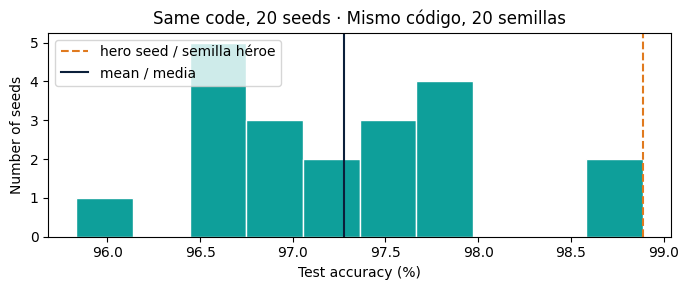

In [5]:
# Importa matplotlib para graficar
import matplotlib.pyplot as plt
# Crea una figura de 7x3 pulgadas
plt.figure(figsize=(7, 3))
# Dibuja el histograma de exactitudes (en %) con 10 barras de color verde azulado
plt.hist(accs * 100, bins=10, color="#0E9F9A", edgecolor="white")
# Línea vertical punteada naranja en la mejor exactitud (la "semilla héroe")
plt.axvline(accs.max() * 100, color="#E07A1F", ls="--", label="hero seed / semilla héroe")
# Línea vertical azul oscuro en la exactitud media
plt.axvline(accs.mean() * 100, color="#0B1F3A", label="mean / media")
# Etiquetas de los ejes y leyenda
plt.xlabel("Test accuracy (%)"); plt.ylabel("Number of seeds"); plt.legend()
# Título, ajuste automático del diseño y muestra la figura
plt.title("Same code, 20 seeds · Mismo código, 20 semillas"); plt.tight_layout(); plt.show()

**EN:** If a paper reports only the best seed, it reports luck. **Report the mean ± SD over several seeds.**  
**ES:** Si un artículo reporta solo la mejor semilla, reporta suerte. **Reporta la media ± DE sobre varias semillas.**

> **🇪🇸 Traducción al español**
>
> Si un artículo reporta solo la mejor semilla, reporta suerte. **Reporta la media ± DE sobre varias semillas.**

## Trick 3 · 87% accuracy on pure noise · 87% de exactitud con puro ruido
**EN:** 100 fake "patients", 5,000 random columns, random labels. There is **nothing** real to learn. The right answer is about 50% (a coin flip).  
**ES:** 100 "pacientes" falsos, 5.000 columnas aleatorias, etiquetas aleatorias. **No hay nada** real que aprender. La respuesta correcta es cerca de 50% (lanzar una moneda).

- **Wrong way · Forma incorrecta:** pick the "best" columns using ALL the data, then test. · Elegir las "mejores" columnas con TODOS los datos y luego evaluar.
- **Right way · Forma correcta:** pick the columns using ONLY the training data, inside a `Pipeline`. · Elegir columnas SOLO con los datos de entrenamiento, dentro de un `Pipeline`.

> **🇪🇸 Traducción al español**
>
> ## Truco 3 · 87 % de exactitud con puro ruido
> 100 "pacientes" falsos, 5.000 columnas aleatorias, etiquetas aleatorias. **No hay nada** real que aprender. La respuesta correcta es cercana al 50 % (lanzar una moneda).
>
> - **Forma incorrecta:** elegir las "mejores" columnas usando TODOS los datos y luego evaluar.
> - **Forma correcta:** elegir las columnas usando SOLO los datos de entrenamiento, dentro de un `Pipeline`.

In [6]:
# Selecciona las k mejores variables según la prueba F de ANOVA
from sklearn.feature_selection import SelectKBest, f_classif
# Clasificador de regresión logística
from sklearn.linear_model import LogisticRegression
# Validación cruzada estratificada y su evaluación
from sklearn.model_selection import StratifiedKFold, cross_val_score
# Encadena pasos (selección + modelo) en un solo objeto
from sklearn.pipeline import make_pipeline

# Generador aleatorio con semilla 0 para que el ruido sea reproducible
rng = np.random.default_rng(0)
# Matriz de 100 filas x 5000 columnas de ruido normal y 100 etiquetas binarias al azar
Xn = rng.normal(size=(100, 5000)); yn = rng.integers(0, 2, 100)   # pure noise / puro ruido
# Validación cruzada de 5 particiones, estratificada y barajada con semilla fija
cv = StratifiedKFold(5, shuffle=True, random_state=0)

# WRONG / INCORRECTO: selection sees the test rows
# ES: INCORRECTO: la selección de variables "ve" las filas de prueba
# Elige las 20 mejores columnas usando TODAS las filas (aquí ocurre la fuga de datos)
X_sel = SelectKBest(f_classif, k=20).fit_transform(Xn, yn)
# Evalúa con validación cruzada sobre las columnas ya elegidas y promedia la exactitud
leaky = cross_val_score(LogisticRegression(max_iter=1000), X_sel, yn, cv=cv).mean()

# RIGHT / CORRECTO: selection happens only on training rows
# ES: CORRECTO: la selección ocurre solo con las filas de entrenamiento de cada partición
# El Pipeline repite la selección dentro de cada partición de entrenamiento, sin ver la de prueba
honest = cross_val_score(make_pipeline(SelectKBest(f_classif, k=20), LogisticRegression(max_iter=1000)),
                         # Continuación del Pipeline: datos con ruido (Xn), etiquetas (yn) y validación cruzada (cv); .mean() promedia la exactitud de las 5 particiones
                         Xn, yn, cv=cv).mean()
# Muestra la exactitud inflada (descubrimiento falso)
print(f"Wrong way / Forma incorrecta: {leaky:.0%}   <- a fake discovery / un descubrimiento falso")
# Muestra la exactitud honesta (cercana al 50 %, como lanzar una moneda)
print(f"Right way / Forma correcta  : {honest:.0%}   <- a coin flip / una moneda al aire")

Wrong way / Forma incorrecta: 87%   <- a fake discovery / un descubrimiento falso
Right way / Forma correcta  : 50%   <- a coin flip / una moneda al aire


**EN:** This is called **data leakage**: information from the test data "leaks" into training. It is like seeing the exam answers before the exam. Kapoor & Narayanan found it in hundreds of published papers ([reproducible.cs.princeton.edu](https://reproducible.cs.princeton.edu/)).  
**ES:** Esto se llama **fuga de datos**: información de los datos de prueba "se filtra" al entrenamiento. Es como ver las respuestas antes del examen. Kapoor y Narayanan la encontraron en cientos de artículos publicados.

> **🇪🇸 Traducción al español**
>
> Esto se llama **fuga de datos** (*data leakage*): información de los datos de prueba "se filtra" al entrenamiento. Es como ver las respuestas antes del examen. Kapoor y Narayanan la encontraron en cientos de artículos publicados ([reproducible.cs.princeton.edu](https://reproducible.cs.princeton.edu/)).

## Trick 4 · Same code, new library · Mismo código, nueva librería
**EN:** In scikit-learn version 0.22, the default number of trees in `RandomForestClassifier` changed from 10 to 100 ([release notes](https://scikit-learn.org/stable/whats_new/v0.22.html)). The same line of code became a different model. We show both.  
**ES:** En scikit-learn 0.22, el número de árboles por defecto en `RandomForestClassifier` cambió de 10 a 100. La misma línea de código se convirtió en otro modelo. Mostramos ambos.

> **🇪🇸 Traducción al español**
>
> ## Truco 4 · Mismo código, nueva librería
> En la versión 0.22 de scikit-learn, el número de árboles por defecto de `RandomForestClassifier` cambió de 10 a 100 ([notas de la versión](https://scikit-learn.org/stable/whats_new/v0.22.html)). La misma línea de código se convirtió en un modelo distinto. Mostramos ambos.

In [8]:
import sklearn
# Carga el conjunto de datos de cáncer de mama
from sklearn.datasets import load_breast_cancer
# Bosque aleatorio de árboles de decisión
from sklearn.ensemble import RandomForestClassifier
# Obtiene variables (Xb) y etiquetas (yb)
Xb, yb = load_breast_cancer(return_X_y=True)
# Validación cruzada de 5 particiones con semilla fija
cv5 = StratifiedKFold(5, shuffle=True, random_state=1)
# Recorre los dos valores por defecto: el antiguo (10 árboles) y el nuevo (100 árboles)
for label, n in [("Old default / antes (10 trees)", 10), ("New default / ahora (100 trees)", 100)]:
    # Evalúa el bosque con n árboles mediante validación cruzada
    s = cross_val_score(RandomForestClassifier(n_estimators=n, random_state=0), Xb, yb, cv=cv5)
    # Imprime la etiqueta y la exactitud media de esa configuración
    print(f"{label:32s}: {s.mean():.4f}")
# Recuerda la solución: fijar (pin) la versión de scikit-learn instalada
print("\nEN: Fix it by pinning versions / ES: Corrígelo fijando versiones -> scikit-learn==" + sklearn.__version__)

Old default / antes (10 trees)  : 0.9631
New default / ahora (100 trees) : 0.9613

EN: Fix it by pinning versions / ES: Corrígelo fijando versiones -> scikit-learn==1.6.1


## 🧠 Takeaway · Conclusión
**EN:** Fix what you can (seeds, versions). Measure what you cannot (run several seeds). **Report the average, not the lucky best.**  
**ES:** Fija lo que puedas (semillas, versiones). Mide lo que no puedas (varias semillas). **Reporta el promedio, no el mejor por suerte.**

> **🇪🇸 Traducción al español**
>
> ## 🧠 Conclusión
> Fija lo que puedas (semillas, versiones). Mide lo que no puedas fijar (ejecuta varias semillas). **Reporta el promedio, no el mejor resultado por suerte.**